<a href="https://colab.research.google.com/github/13rustam/Zhanakorgan_Agriculture/blob/main/13_PyStac_NDVI_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pystac-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 13.1 MB/s eta 0:00:00


In [2]:
from pystac_client import Client

In [3]:
catalog = Client.open(
    'https://earth-search.aws.element84.com/v1'
)

In [4]:
for collection in catalog.get_collections():
  print(collection.id)

sentinel-2-pre-c1-l2a
cop-dem-glo-30
naip
cop-dem-glo-90
landsat-c2-l2
sentinel-2-l2a
sentinel-2-l1c
sentinel-2-c1-l2a
sentinel-1-grd


In [5]:
roi = [67.311429, 43.551136, 67.386264, 43.59439]

In [6]:
search = catalog.search(
    collections = ['sentinel-2-c1-l2a'],
    bbox = roi,
    datetime = '2025'
)

In [7]:
item = search.item_collection()

/usr/local/lib/python3.13/dist-packages/pystac/extensions/storage.py:724: UserWarning: Could not parse bucket/account from href. The following assets were not migrated: ['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail']
  warnings.warn(


In [8]:
len(item)

168

In [9]:
item[0].properties['proj:code']

'EPSG:32642'

In [10]:
item[0].assets.keys()

dict_keys(['red', 'green', 'blue', 'visual', 'nir', 'swir22', 'rededge2', 'rededge3', 'rededge1', 'swir16', 'wvp', 'nir08', 'scl', 'aot', 'coastal', 'nir09', 'cloud', 'snow', 'preview', 'granule_metadata', 'tileinfo_metadata', 'product_metadata', 'thumbnail'])

In [11]:
!pip install -q stackstac

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.3/64.3 kB 4.1 MB/s eta 0:00:00


In [12]:
from stackstac import stack

In [13]:
ds_stack = stack(
    item,
    assets = ['nir','red', 'scl'],
    bounds_latlon = roi,
    epsg = 32642,
    resolution = 10
)

In [14]:
ds = (
    ds_stack.to_dataset('band')
    .drop_dims('band')
    .reset_coords(drop = True)
    .drop_attrs()

)

In [15]:
mask = ds.scl.isin([0,1,3,8,9,10,11]).astype(int)
ds_mask = ds[['nir','red']].where(mask == 0)

In [16]:
red = ds_mask['red']
nir = ds_mask['nir']
ndvi = (nir - red) / (nir + red)

In [17]:
ndvi_monthly = ndvi.resample(time = 'ME').max('time')

In [18]:
ndvi_mean = ndvi_monthly.mean(dim = 'time')

In [19]:
from dask.diagnostics import ProgressBar

In [20]:
import warnings
warnings.filterwarnings('ignore', category = RuntimeWarning)
import logging
logging.getLogger().setLevel(logging.ERROR)

In [21]:
with ProgressBar():
  ndvi_mean = ndvi_mean.compute()

[########################################] | 100% Completed | 116.26 s


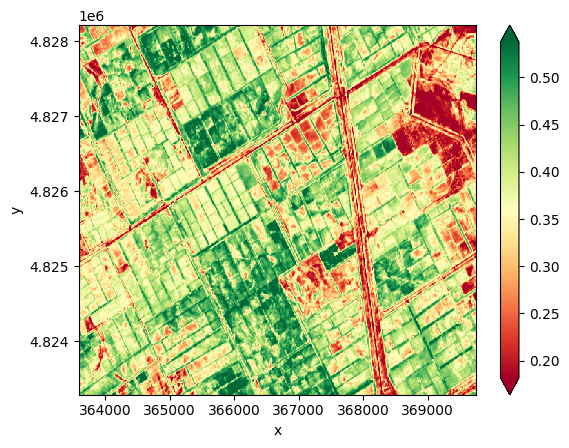

In [22]:
ndvi_mean.plot(
    robust = True,
    cmap = 'RdYlGn'
)

In [23]:
from skimage.segmentation import slic

In [41]:
ndvi_segment = slic(
    image = ndvi_mean,
    n_segments = 500,
    compactness = 0.1,
    start_label = 1,
    channel_axis = None

)

In [25]:
from scipy.ndimage import mean

In [42]:
ndvi_seg_mean = mean(
    input =  ndvi_mean.values,
    labels = ndvi_segment,
    index = ndvi_segment
)

In [36]:
import xarray as xr

In [43]:
result = xr.DataArray(
    ndvi_seg_mean,
    dims = ndvi_mean.dims,
    coords = ndvi_mean.coords
)

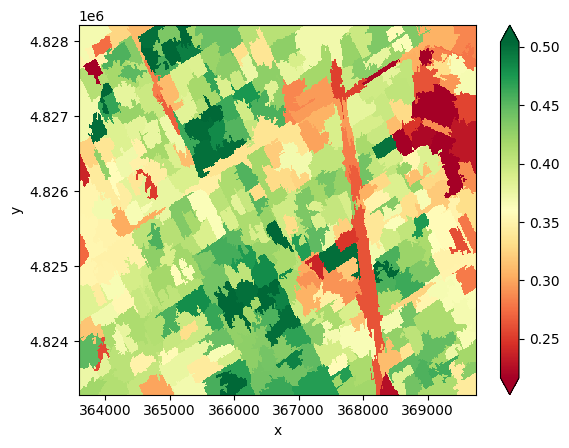

In [44]:
result.plot(
    robust =True,
    cmap = 'RdYlGn'
)

In [45]:
import matplotlib.pyplot as plt

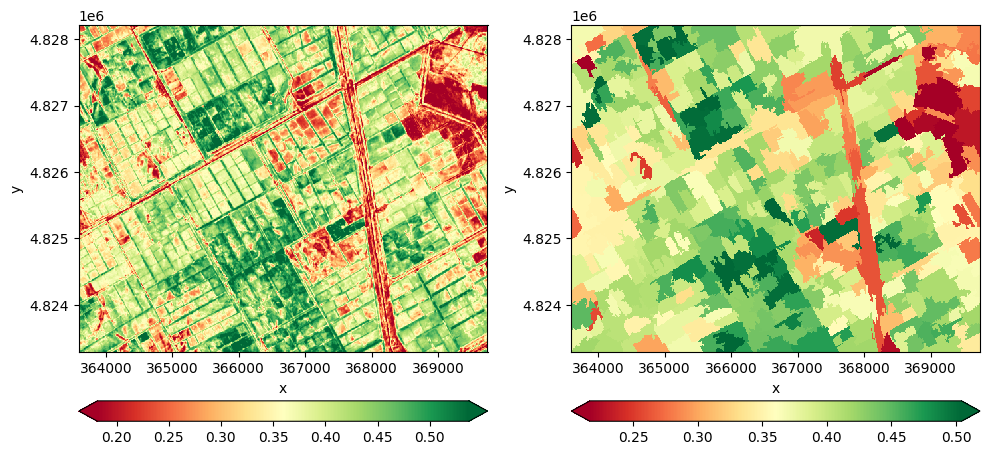

In [46]:
fig, ax = plt.subplots(1, 2, figsize = (10,10))

ndvi_mean.plot(
    ax = ax[0],
    robust = True,
    cmap = 'RdYlGn',
    cbar_kwargs = {'orientation': 'horizontal', 'pad': 0.05}
)

result.plot(
    ax = ax[1],
    robust = True,
    cmap = 'RdYlGn',
    cbar_kwargs = {'orientation': 'horizontal', 'pad': 0.05}
)

for i in ax:
  i.set_aspect('equal', adjustable = 'box')


plt.tight_layout()

plt.savefig('ndvi_segment.png', dpi = 360, bbox_inches = 'tight')